In [16]:
import pickle
import pandas as pd
import matplotlib.pyplot as plt

In [17]:
#Read the pickle file from stubs
with open('../tracker_stubs/ball_detections.pkl', 'rb') as f:
    ball_positions = pickle.load(f)

In [18]:
ball_positions


[{},
 {},
 {},
 {},
 {},
 {},
 {},
 {},
 {},
 {},
 {},
 {},
 {},
 {},
 {},
 {1: [980.54443359375, 309.815673828125, 998.158447265625, 329.1753234863281]},
 {1: [968.822998046875,
   341.2142333984375,
   987.8201904296875,
   361.96337890625]},
 {},
 {},
 {},
 {},
 {},
 {},
 {1: [911.32470703125, 543.821533203125, 931.03125, 564.7239379882812]},
 {},
 {},
 {1: [895.4681396484375,
   617.9404907226562,
   912.361083984375,
   635.2855224609375]},
 {1: [886.3822631835938,
   635.68212890625,
   902.9613647460938,
   652.883056640625]},
 {1: [873.9385986328125,
   638.3980712890625,
   895.3289794921875,
   658.788330078125]},
 {1: [871.5884399414062,
   645.0022583007812,
   886.91162109375,
   662.5384521484375]},
 {1: [860.2527465820312,
   645.8490600585938,
   881.3241577148438,
   669.90087890625]},
 {1: [860.28955078125, 645.837890625, 881.328369140625, 669.8633422851562]},
 {},
 {},
 {},
 {},
 {1: [822.8285522460938,
   686.9363403320312,
   838.0286865234375,
   703.0986938476562

In [19]:
print(f"Total number of frames: {len(ball_positions)}")

Total number of frames: 929


In [20]:
ball_positions = [x.get(1,[]) for x in ball_positions]
    # convert the list into pandas dataframe
df_ball_positions = pd.DataFrame(ball_positions,columns=['x1','y1','x2','y2'])

    # interpolate the missing values
df_ball_positions = df_ball_positions.interpolate()
df_ball_positions = df_ball_positions.bfill()

df_ball_positions['mid_y'] = (df_ball_positions['y1'] + df_ball_positions['y2']) / 2
df_ball_positions['mid_y_rolling_mean'] = df_ball_positions['mid_y'].rolling(window =5,min_periods=1, center =False).mean()

df_ball_positions['delta_y'] = df_ball_positions['mid_y_rolling_mean'].diff()

/var/folders/ys/s08yrsnx79sckv_k7pkp7d7w0000gn/T/ipykernel_747/3701847517.py:3: Pandas4Warning: Constructing a DataFrame from a list of sequences with mismatched lengths is deprecated and will raise in a future version. The shorter sequences are currently padded with NaN; make all sequences the same length before constructing instead.
  df_ball_positions = pd.DataFrame(ball_positions,columns=['x1','y1','x2','y2'])


In [21]:
df_ball_positions

,x1,y1,x2,y2,mid_y,mid_y_rolling_mean,delta_y
0,980.544434,309.815674,998.158447,329.175323,319.495499,319.495499,NaN
1,980.544434,309.815674,998.158447,329.175323,319.495499,319.495499,0.0
2,980.544434,309.815674,998.158447,329.175323,319.495499,319.495499,0.0
3,980.544434,309.815674,998.158447,329.175323,319.495499,319.495499,0.0
4,980.544434,309.815674,998.158447,329.175323,319.495499,319.495499,0.0
...,...,...,...,...,...,...,...
924,1160.508301,518.690308,1171.048218,530.746521,524.718414,524.718414,0.0
925,1160.508301,518.690308,1171.048218,530.746521,524.718414,524.718414,0.0
926,1160.508301,518.690308,1171.048218,530.746521,524.718414,524.718414,0.0
927,1160.508301,518.690308,1171.048218,530.746521,524.718414,524.718414,0.0


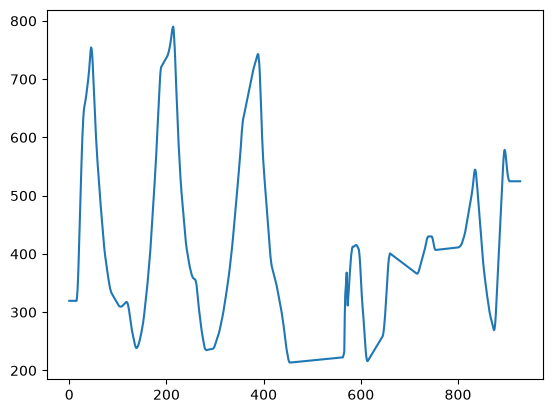

In [22]:
#plot mid_y_rolling_mean
plt.plot(df_ball_positions['mid_y_rolling_mean']) 

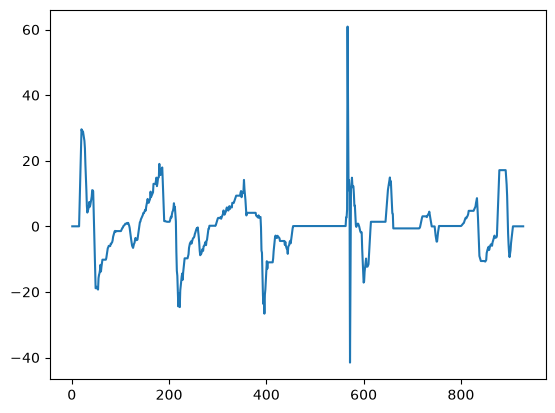

In [23]:
plt.plot(df_ball_positions['delta_y'])


In [24]:
df_ball_positions['ball_hit'] = 0

In [25]:
minimum_change_frames_for_hit = 25
for i in range(1,len(df_ball_positions)- int(minimum_change_frames_for_hit*1.2) ):
    negative_position_change = df_ball_positions['delta_y'].iloc[i] >0 and df_ball_positions['delta_y'].iloc[i+1] <0
    positive_position_change = df_ball_positions['delta_y'].iloc[i] <0 and df_ball_positions['delta_y'].iloc[i+1] >0

    if negative_position_change or positive_position_change:
        change_count = 0 
        for change_frame in range(i+1, i+int(minimum_change_frames_for_hit*1.2)+1):
            negative_position_change_following_frame = df_ball_positions['delta_y'].iloc[i] >0 and df_ball_positions['delta_y'].iloc[change_frame] <0
            positive_position_change_following_frame = df_ball_positions['delta_y'].iloc[i] <0 and df_ball_positions['delta_y'].iloc[change_frame] >0

            if negative_position_change and negative_position_change_following_frame:
                change_count+=1
            elif positive_position_change and positive_position_change_following_frame:
                change_count+=1
    
        if change_count>minimum_change_frames_for_hit-1:
            df_ball_positions['ball_hit'].iloc[i] = 1

frame_nums_with_ball_hits = df_ball_positions[df_ball_positions['ball_hit']==1].index.tolist()

/var/folders/ys/s08yrsnx79sckv_k7pkp7d7w0000gn/T/ipykernel_747/3752280353.py:18: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

Try using '.loc[row_indexer, col_indexer] = value' instead, to perform the assignment in a single step.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#chained-assignment
  df_ball_positions['ball_hit'].iloc[i] = 1


In [26]:
df_ball_positions['ball_hit'] = 0

minimum_change_frames_for_hit = 25
window = int(minimum_change_frames_for_hit * 1.2)

delta_y = df_ball_positions['delta_y']

for i in range(1, len(df_ball_positions) - window - 1):

    # Detect a direction reversal
    negative_change = delta_y.iloc[i] > 0 and delta_y.iloc[i + 1] < 0
    positive_change = delta_y.iloc[i] < 0 and delta_y.iloc[i + 1] > 0

    if negative_change or positive_change:

        # Count how many subsequent frames continue in the new direction
        following= delta_y.iloc[i + 2:i + window + 1]

        if negative_change:
            change_count = (following < 0).sum() 
        else:
            change_count = (following > 0).sum()

        if change_count >= minimum_change_frames_for_hit:
            df_ball_positions.loc[i, 'ball_hit'] = 1

frame_nums_with_ball_hits = df_ball_positions[df_ball_positions['ball_hit'] == 1].index.tolist()



In [27]:
print("Number of frames with ball hits:", len(frame_nums_with_ball_hits))
print("Frame numbers with ball hits:", frame_nums_with_ball_hits)

Number of frames with ball hits: 10
Frame numbers with ball hits: [45, 138, 214, 282, 388, 454, 614, 660, 754, 835]


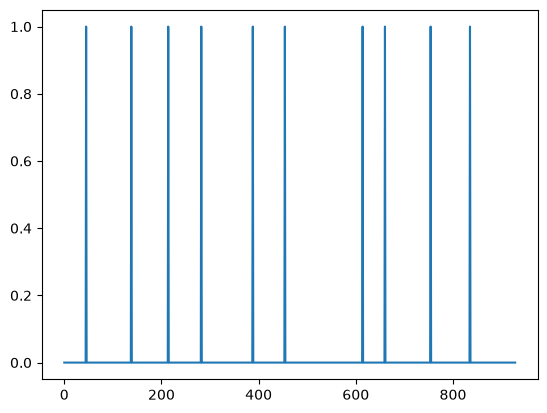

In [28]:
plt.plot(df_ball_positions['ball_hit']==1)

In [29]:
df_ball_positions[df_ball_positions['ball_hit']==1]


,x1,y1,x2,y2,mid_y,mid_y_rolling_mean,delta_y,ball_hit
45,773.001953,741.170288,791.578552,762.098511,751.634399,754.382727,4.652954,1
138,934.169449,232.490135,947.562744,246.705025,239.597580,238.428249,-0.952226,1
214,616.092163,774.733337,640.481079,800.952942,787.843140,790.200220,1.498233,1
282,699.203430,227.777035,712.782120,242.696136,235.236586,234.895114,-0.695891,1
388,1294.862793,738.828918,1314.239136,760.495789,749.662354,743.109875,2.849457,1
454,1175.207081,208.068677,1184.642788,219.191863,213.630270,213.488607,-0.674211,1
614,782.961963,212.711409,794.475525,224.357499,218.534454,215.764812,-0.899945,1
660,878.891985,392.016101,891.684137,407.403116,399.709608,400.976249,3.819980,1
754,963.109953,400.814693,974.556298,413.131391,406.973042,406.768666,-0.798525,1
835,726.763306,532.868408,739.227397,546.017314,539.442861,544.655206,2.819840,1


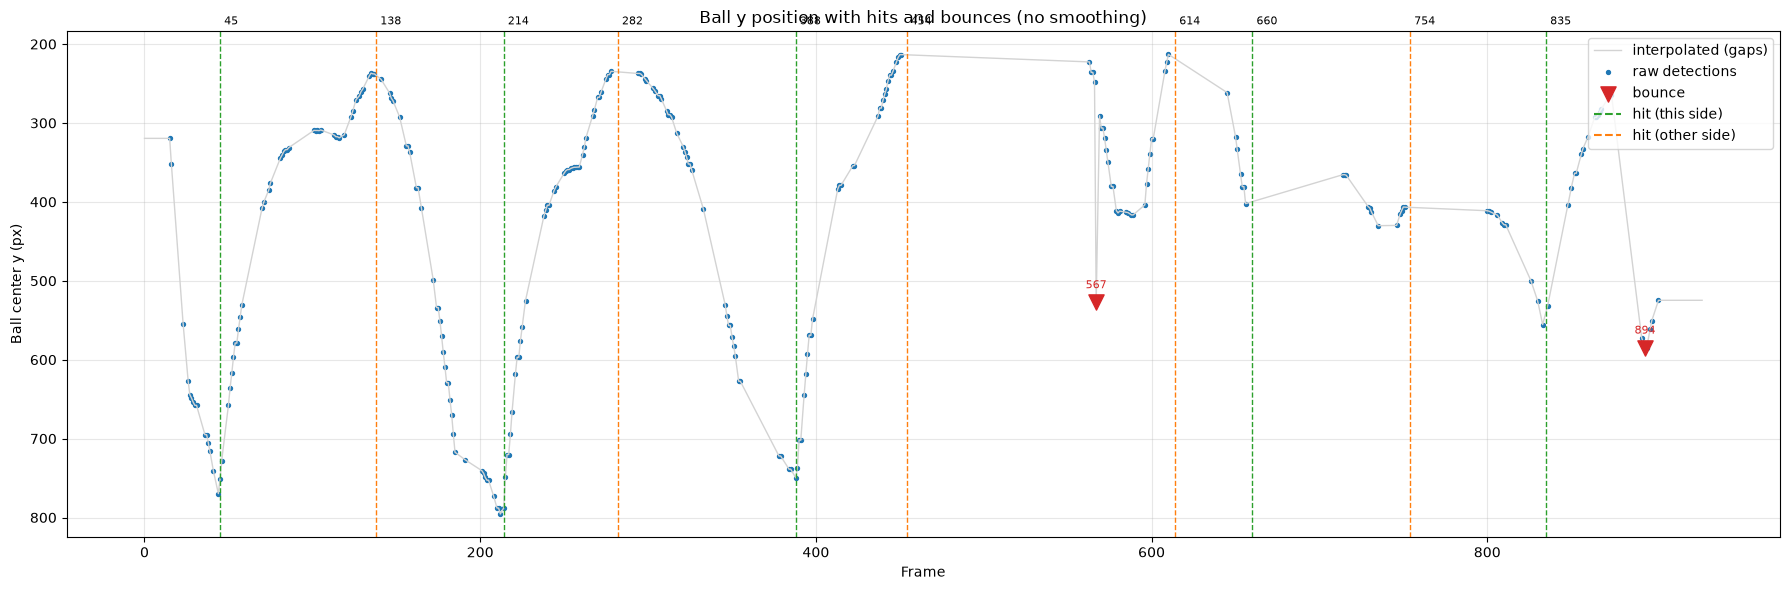

Hits: [45, 138, 214, 282, 388, 454, 614, 660, 754, 835]
Bounces: [567, 894]


In [30]:
import sys, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append('..')  # notebook is in training/, so go up to the project root
from trackers import BallTracker

# load raw ball detections
with open('../tracker_stubs/ball_detections.pkl', 'rb') as f:
    raw_detections = pickle.load(f)

ball_tracker = BallTracker(model_path='../models/yolo5_last.pt')
ball_detections = ball_tracker.interpolate_ball_positions(raw_detections)

hit_frames, hit_this_side, hit_other_side = ball_tracker.get_ball_shot_frames(ball_detections)
bounce_frames = ball_tracker.get_ball_bounce_frames(ball_detections, hit_frames)

# raw (unsmoothed) ball center y
raw = pd.DataFrame([d.get(1, [np.nan] * 4) for d in raw_detections],
                   columns=['x1', 'y1', 'x2', 'y2'])
raw_y = (raw['y1'] + raw['y2']) / 2
interp_y = raw_y.interpolate().bfill().ffill()   # only fills gaps, no smoothing
frames = np.arange(len(raw_y))

fig, ax = plt.subplots(figsize=(18, 6))
ax.plot(frames, interp_y, color='lightgray', lw=1, label='interpolated (gaps)')
ax.scatter(frames, raw_y, s=8, color='tab:blue', label='raw detections')

for f in hit_this_side:
    ax.axvline(f, color='tab:green', ls='--', lw=1)
for f in hit_other_side:
    ax.axvline(f, color='tab:orange', ls='--', lw=1)
ax.scatter(bounce_frames, interp_y.iloc[bounce_frames], s=120, marker='v',
           color='tab:red', zorder=5, label='bounce')

for f in bounce_frames:
    ax.annotate(str(f), (f, interp_y.iloc[f]), textcoords='offset points',
                xytext=(0, 10), ha='center', color='tab:red', fontsize=8)
for f in hit_frames:
    ax.annotate(str(f), (f, ax.get_ylim()[0]), textcoords='offset points',
                xytext=(3, 5), fontsize=8, color='black')

# legend entries for the hit lines
ax.plot([], [], color='tab:green', ls='--', label='hit (this side)')
ax.plot([], [], color='tab:orange', ls='--', label='hit (other side)')

ax.invert_yaxis()  # image y grows downward, flip so "up" on screen is up
ax.set_xlabel('Frame')
ax.set_ylabel('Ball center y (px)')
ax.set_title('Ball y position with hits and bounces (no smoothing)')
ax.legend(loc='upper right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print('Hits:', hit_frames)
print('Bounces:', bounce_frames)

Ball shot frames: [45, 138, 214, 282, 388, 454, 614, 660, 754, 835]
Ball bounce frames: [119, 185, 259, 354, 439, 596, 654, 746, 809]


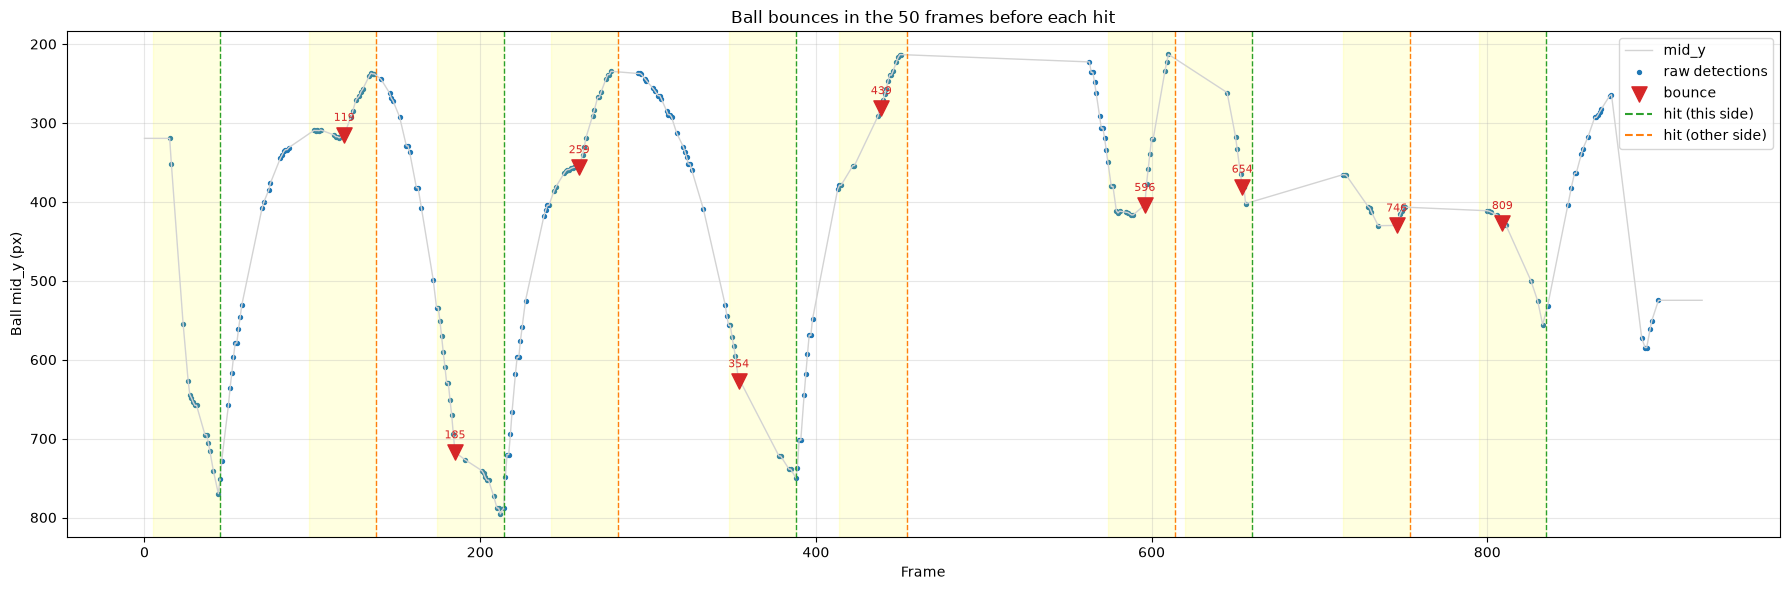

In [35]:
import sys, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append('..')
from trackers import BallTracker


def get_ball_bounce_frames(ball_positions, ball_shot_frames):

    ball_positions = [x.get(1,[np.nan]*4) for x in ball_positions]
    # convert the list into pandas dataframe
    df_ball_positions = pd.DataFrame(ball_positions,columns=['x1','y1','x2','y2'])

    df_ball_positions['mid_y'] = (df_ball_positions['y1'] + df_ball_positions['y2']) / 2

    # remove one frame jumps (false detections)
    df_ball_positions['mid_y_median'] = df_ball_positions['mid_y'].rolling(window =7,min_periods=1, center =True).median()
    outliers = (df_ball_positions['mid_y'] - df_ball_positions['mid_y_median']).abs() > 50
    df_ball_positions.loc[outliers, 'mid_y'] = np.nan

    # interpolate the missing values (no smoothing)
    df_ball_positions['mid_y'] = df_ball_positions['mid_y'].interpolate()
    df_ball_positions['mid_y'] = df_ball_positions['mid_y'].bfill().ffill()

    df_ball_positions['delta_y'] = df_ball_positions['mid_y'].diff()

    #Logic to find the ball bounce frames
    df_ball_positions['ball_bounce'] = 0

    frames_before_hit = 50          # search window before each hit
    frames_to_skip_near_hit = 4     # ignore the kink caused by the hit itself
    frames_for_direction = 3        # frames used to check direction before and after
    minimum_change_for_bounce = 0.5 # px/frame, small so even small variations count

    delta_y = df_ball_positions['delta_y']
    ball_shot_frames = sorted(ball_shot_frames)

    for hit_index, hit_frame in enumerate(ball_shot_frames):

        # first hit is the serve, no bounce before it
        if hit_index == 0:
            continue

        previous_hit_frame = ball_shot_frames[hit_index - 1]

        start = max(hit_frame - frames_before_hit, previous_hit_frame + frames_to_skip_near_hit, frames_for_direction)
        end = hit_frame - frames_to_skip_near_hit

        best_frame = None
        best_change = 0

        for i in range(start, end):

            # direction before and after frame i
            before = delta_y.iloc[i - frames_for_direction + 1:i + 1].mean()
            after = delta_y.iloc[i + 1:i + frames_for_direction + 1].mean()

            # ball was going down the screen, then went up (or slowed down)
            change = before - after

            if change > best_change:
                best_change = change
                best_frame = i

        if best_frame is not None and best_change >= minimum_change_for_bounce:
            df_ball_positions.loc[best_frame, 'ball_bounce'] = 1

    frame_nums_with_ball_bounces = df_ball_positions[df_ball_positions['ball_bounce'] == 1].index.tolist()

    return frame_nums_with_ball_bounces, df_ball_positions


with open('../tracker_stubs/ball_detections.pkl', 'rb') as f:
    raw_ball_detections = pickle.load(f)

ball_tracker = BallTracker(model_path = '../models/yolo5_last.pt')
ball_detections = ball_tracker.interpolate_ball_positions(raw_ball_detections)

ball_shot_frames, ball_hit_this_side, ball_hit_other_side = ball_tracker.get_ball_shot_frames(ball_detections)
ball_bounce_frames, df_ball_positions = get_ball_bounce_frames(raw_ball_detections, ball_shot_frames)

print("Ball shot frames:", ball_shot_frames)
print("Ball bounce frames:", ball_bounce_frames)


# Plot ball y with hits and bounces
detected = [1 in x for x in raw_ball_detections]
df_ball_positions['detected'] = detected

plt.figure(figsize=(18, 6))
plt.plot(df_ball_positions.index, df_ball_positions['mid_y'], color='lightgray', lw=1, label='mid_y')
df_detected = df_ball_positions[df_ball_positions['detected']]
plt.scatter(df_detected.index, df_detected['mid_y'], s=8, color='tab:blue', label='raw detections')

for hit_frame in ball_shot_frames:
    plt.axvspan(max(hit_frame - 40, 0), hit_frame, color='yellow', alpha=0.12)
for hit_frame in ball_hit_this_side:
    plt.axvline(hit_frame, color='tab:green', ls='--', lw=1)
for hit_frame in ball_hit_other_side:
    plt.axvline(hit_frame, color='tab:orange', ls='--', lw=1)

plt.scatter(ball_bounce_frames, df_ball_positions.loc[ball_bounce_frames, 'mid_y'], s=120, marker='v', color='tab:red', zorder=5, label='bounce')
for bounce_frame in ball_bounce_frames:
    plt.annotate(str(bounce_frame), (bounce_frame, df_ball_positions.loc[bounce_frame, 'mid_y']), textcoords='offset points', xytext=(0, 10), ha='center', color='tab:red', fontsize=8)

plt.plot([], [], color='tab:green', ls='--', label='hit (this side)')
plt.plot([], [], color='tab:orange', ls='--', label='hit (other side)')
plt.gca().invert_yaxis()
plt.xlabel('Frame')
plt.ylabel('Ball mid_y (px)')
plt.title('Ball bounces in the 50 frames before each hit')
plt.legend(loc='upper right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()